# 01 — Simulación de los años de pago

**Los años de pago no están en la base de ICETEX: se simulan.** Este cuaderno define la variable
objetivo del proyecto (`anios_pago`) y comprueba que sea un problema de aprendizaje razonable.
Los resultados de los modelos describen este simulador, no el comportamiento real de ICETEX.

Todo el código está en `src/proyecto_ml/` (`data.py` y `simulation.py`).

In [1]:
import sys
sys.path.append("../src")  # por si el paquete no está instalado con pip install -e .

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

from proyecto_ml import simulation as sim
from proyecto_ml.data import cargar_convocatorias

RESULTADOS = Path("..") / "resultados"
RESULTADOS.mkdir(exist_ok=True)
pd.set_option("display.float_format", "{:,.2f}".format)

## Datos

In [2]:
df = cargar_convocatorias()
print(df.shape)
df.head()

(8716, 9)


,estrato,anio_inicio,valor_comprometido,genero,departamento,ciudad,programa,tipo_institucion,programa_academico
0,3,2018,"4,301,536.80",M,DISTRITO CAPITAL,BOGOTA D.C.,COMPETENCIAS GERENCIALES,IES,GESTIÓN ESTRATÉGICA PARA LAS PYMES
1,3,2018,"4,301,536.80",M,DISTRITO CAPITAL,BOGOTA D.C.,COMPETENCIAS GERENCIALES,IES,GESTIÓN ESTRATÉGICA PARA LAS PYMES
2,5,2018,"4,301,536.80",F,DISTRITO CAPITAL,BOGOTA D.C.,COMPETENCIAS GERENCIALES,IES,GESTIÓN ESTRATÉGICA PARA LAS PYMES
3,4,2018,"4,301,536.80",F,DISTRITO CAPITAL,BOGOTA D.C.,COMPETENCIAS GERENCIALES,IES,GESTIÓN ESTRATÉGICA PARA LAS PYMES
4,5,2017,"5,474,339.20",M,VALLE DEL CAUCA,JAMUNDI,COMPETENCIAS GERENCIALES,IES,GESTIÓN ESTRATÉGICA PARA LAS PYMES - PRESENCIAL


## Supuestos del simulador

Cada año la persona abona un porcentaje de lo que gana, según su estrato. Los años de pago son el
tiempo que tarda el abono acumulado en alcanzar el valor comprometido (con la fracción del último año).

In [3]:
supuestos = pd.DataFrame({
    "supuesto": [
        "Ingreso base",
        "Salario mínimo después de 2024",
        "Porcentaje del ingreso que se abona",
        "Meses trabajados por año",
        "Factor de ingreso de cada persona",
        "Efecto del programa Gerenciales",
        "Horizonte máximo",
    ],
    "valor": [
        "SMMLV de cada año (2014-2024) x meses trabajados",
        f"crece {sim.crecimiento_promedio_smmlv():.1%} anual (promedio 2014-2024)",
        ", ".join(f"E{e}: {p:.1%}" for e, p in sim.PORCENTAJE_POR_ESTRATO.items()),
        f"entero al azar entre {sim.MESES_MIN} y {sim.MESES_MAX}, cada año",
        f"lognormal, sigma = {sim.SIGMA_INGRESO}, fijo para cada persona",
        f"x {sim.FACTOR_GERENCIALES} (supuesto)",
        f"{sim.HORIZONTE} años",
    ],
})
supuestos

,supuesto,valor
0,Ingreso base,SMMLV de cada año (2014-2024) x meses trabajados
1,Salario mínimo después de 2024,crece 7.8% anual (promedio 2014-2024)
2,Porcentaje del ingreso que se abona,"E1: 2.5%, E2: 4.5%, E3: 6.5%, E4: 8.5%, E5: 10..."
3,Meses trabajados por año,"entero al azar entre 8 y 12, cada año"
4,Factor de ingreso de cada persona,"lognormal, sigma = 0.25, fijo para cada persona"
5,Efecto del programa Gerenciales,x 1.25 (supuesto)
6,Horizonte máximo,60 años


## Variable objetivo: `anios_pago`

In [4]:
datos = sim.agregar_objetivo(df, semilla=2026)
anios, censurados = sim.simular_anios_de_pago(df, semilla=2026)
print("Personas que no terminan de pagar en el horizonte:", int(censurados.sum()))
datos["anios_pago"].describe().to_frame().T

Personas que no terminan de pagar en el horizonte: 0


,count,mean,std,min,25%,50%,75%,max
anios_pago,"8,716.00",5.80,3.06,0.70,3.43,5.34,7.65,23.26


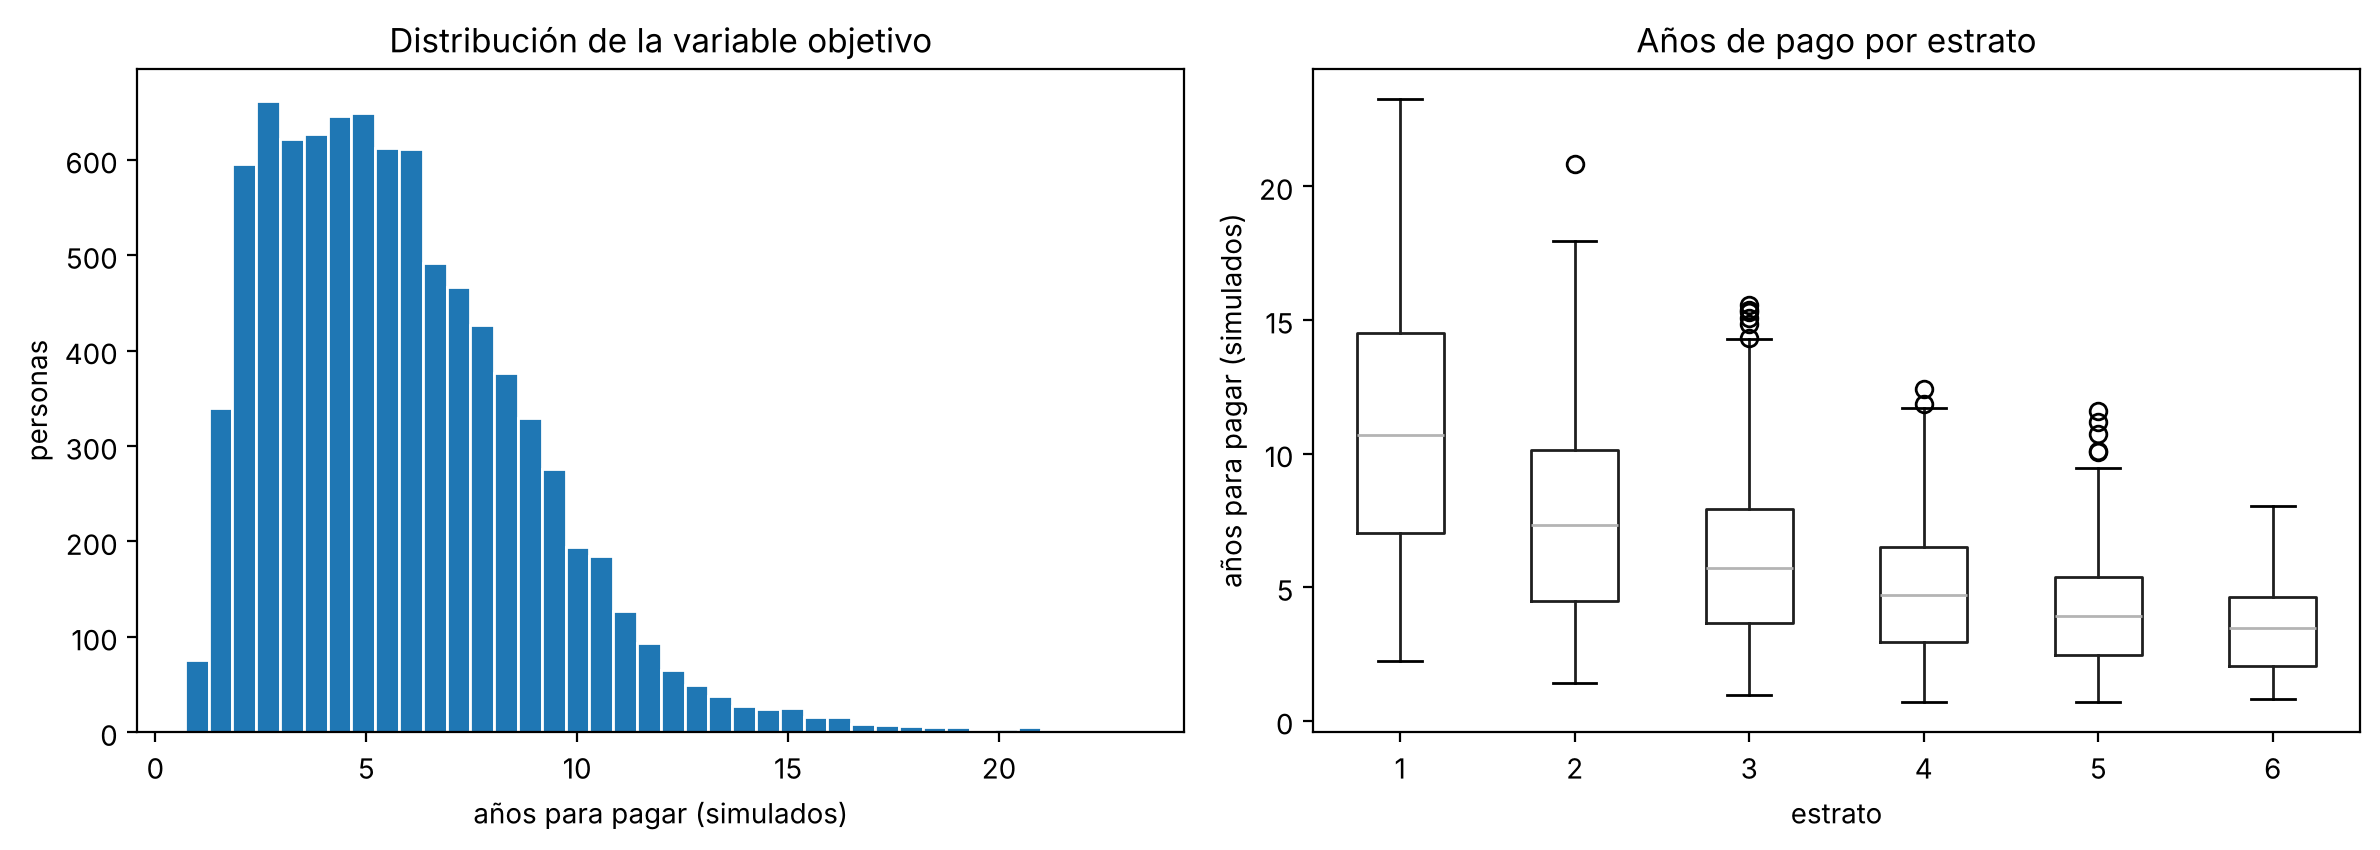

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(datos["anios_pago"], bins=40, color="tab:blue", edgecolor="white")
axes[0].set_xlabel("años para pagar (simulados)")
axes[0].set_ylabel("personas")
axes[0].set_title("Distribución de la variable objetivo")

datos.boxplot(column="anios_pago", by="estrato", ax=axes[1], grid=False)
axes[1].set_xlabel("estrato")
axes[1].set_ylabel("años para pagar (simulados)")
axes[1].set_title("Años de pago por estrato")
plt.suptitle("")
plt.tight_layout()
plt.savefig(RESULTADOS / "01_objetivo_simulado.png", dpi=150)
plt.show()

## ¿Es una fórmula exacta de las variables? (comprobación)

Si los años salieran de una fórmula exacta de estrato, año de inicio y valor comprometido, cualquier árbol la
adivinaría y comparar modelos no diría nada. Se ajusta un Random Forest con solo esas tres variables, con y sin azar.

In [6]:
X = df[["estrato", "anio_inicio", "valor_comprometido"]]
sin_azar, _ = sim.simular_anios_de_pago(df, con_azar=False)

resultados = []
for nombre, y in [("sin azar (fórmula pura)", sin_azar), ("con azar (objetivo del proyecto)", anios)]:
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=0)
    rf = RandomForestRegressor(n_estimators=200, random_state=0).fit(X_tr, y_tr)
    resultados.append({"objetivo": nombre, "R2 en prueba": r2_score(y_te, rf.predict(X_te))})
pd.DataFrame(resultados)

,objetivo,R2 en prueba
0,sin azar (fórmula pura),1.00
1,con azar (objetivo del proyecto),0.82


### Mi análisis
*(Escríbelo con tus palabras. Preguntas para guiarte: ¿por qué el R² es 1 sin azar? ¿Qué le agrega el azar al problema? ¿Qué parte de la variable objetivo sigue siendo imposible de predecir con estas tres variables y por qué? ¿Qué dirías en la oral sobre el hecho de que la variable objetivo es simulada?)*